In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

In [ ]:
dataset = load_dataset("fancyzhx/ag_news")

In [4]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [5]:
print(dataset["train"].features)

{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}


In [10]:
df = pd.DataFrame(dataset["train"])
print(df.head())

                                                text  label
0  Wall St. Bears Claw Back Into the Black (Reute...      2
1  Carlyle Looks Toward Commercial Aerospace (Reu...      2
2  Oil and Economy Cloud Stocks' Outlook (Reuters...      2
3  Iraq Halts Oil Exports from Main Southern Pipe...      2
4  Oil prices soar to all-time record, posing new...      2


In [11]:
print(df.shape)

(120000, 2)


In [12]:
print(df.isnull().sum())

text     0
label    0
dtype: int64


In [13]:
print(df.duplicated().sum())

0


In [15]:
label_counts = df["label"].value_counts().sort_index()
print(label_counts)

label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64


In [ ]:
print(df["label"])

RangeIndex(start=0, stop=120000, step=1)


In [23]:
label_names = dataset["train"].features["label"].names
for i, name in enumerate(label_names):
    print(f"{i} = {name}")

0 = World
1 = Sports
2 = Business
3 = Sci/Tech


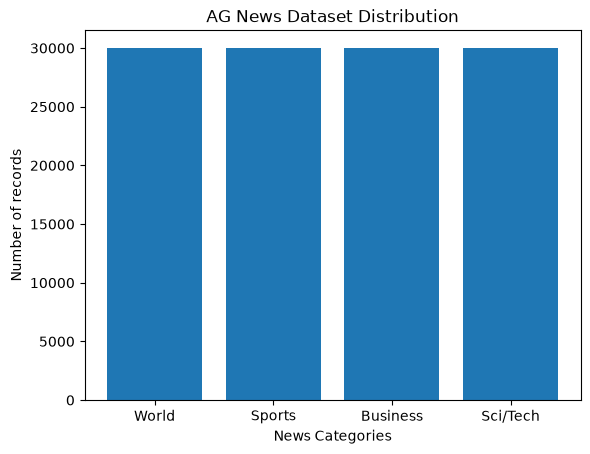

In [24]:
plt.Figure(figsize=(8,5))

plt.bar(label_names, label_counts.values)

plt.xlabel("News Categories")
plt.ylabel("Number of records")
plt.title("AG News Dataset Distribution")

plt.show()

In [25]:
df["text_length"] = df["text"].apply(
    lambda x: len(x.split())
)

print("Average words:", df["text_length"].mean())

print("Maximum words:", df["text_length"].max())

print("Minimum words:", df["text_length"].min())

Average words: 37.84745
Maximum words: 177
Minimum words: 8
